In [2]:
import os 
import seaborn as sns
import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 
from sklearn.ensemble import RandomForestRegressor 
from sklearn.metrics import ( mean_absolute_error, median_absolute_error, r2_score, )
from sklearn.model_selection import train_test_split

In [3]:
df_atypical = pd.read_csv("../data/processed/docentes_enoe_reporte_limpio.csv")
df_atypical.columns =df_atypical.columns.str.lower().str.strip()
df_atypical.head()

C:\Users\David\AppData\Local\Temp\ipykernel_24560\3726760074.py:1: DtypeWarning: Columns (22: par_c, 23: sex, 24: eda_x, 25: nac_dia, 26: nac_mes, 27: nac_anio, 28: l_nac_c, 29: cs_p12, 30: cs_p13_1, 31: cs_p13_2, 35: cs_p17, 37: e_con, 38: cs_p20a_1, 39: cs_p20a_c, 40: cs_p20b_1, 41: cs_p20b_c, 208: p4a_1, 209: p4b, 220: p5) have mixed types. Specify dtype option on import or set low_memory=False.
  df_atypical = pd.read_csv("../data/processed/docentes_enoe_reporte_limpio.csv")


,r_def,cve_loc,cve_mun_x,est,est_d_tri,est_d_men,cve_ageb,t_loc_tri,t_loc_men,cd_a_x,...,p5f14,p5f15,p5f99,ur_y,tipo_y,mes_cal_y,fac_tri_y,fac_men_y,cve_mun_y,cvegeo_y
0,0,\N,6,40,672,672,0,1,1,1,...,14,\N,\N,1,1,5,2044,7421,6,9006
1,0,\N,120,40,772,772,0,1,1,2,...,14,\N,\N,1,1,4,680,2138,120,14120
2,0,\N,18,40,914,914,0,2,2,3,...,14,\N,\N,1,1,6,384,1390,18,19018
3,0,\N,114,20,961,961,0,1,1,4,...,14,\N,\N,1,1,4,143,485,114,21114
4,0,\N,31,20,706,706,0,2,2,5,...,14,\N,\N,1,1,5,122,431,31,11031


In [4]:
df_atypical = df_atypical.loc[:, ~df_atypical.columns.duplicated()]
df_atypical.head()

,r_def,cve_loc,cve_mun_x,est,est_d_tri,est_d_men,cve_ageb,t_loc_tri,t_loc_men,cd_a_x,...,p5f14,p5f15,p5f99,ur_y,tipo_y,mes_cal_y,fac_tri_y,fac_men_y,cve_mun_y,cvegeo_y
0,0,\N,6,40,672,672,0,1,1,1,...,14,\N,\N,1,1,5,2044,7421,6,9006
1,0,\N,120,40,772,772,0,1,1,2,...,14,\N,\N,1,1,4,680,2138,120,14120
2,0,\N,18,40,914,914,0,2,2,3,...,14,\N,\N,1,1,6,384,1390,18,19018
3,0,\N,114,20,961,961,0,1,1,4,...,14,\N,\N,1,1,4,143,485,114,21114
4,0,\N,31,20,706,706,0,2,2,5,...,14,\N,\N,1,1,5,122,431,31,11031


In [5]:
print(df_atypical.columns.tolist())

['r_def', 'cve_loc', 'cve_mun_x', 'est', 'est_d_tri', 'est_d_men', 'cve_ageb', 't_loc_tri', 't_loc_men', 'cd_a_x', 'cve_ent', 'con', 'upm', 'd_sem', 'n_pro_viv_x', 'v_sel', 'n_hog', 'h_mud', 'n_ent_x', 'per_x', 'n_ren', 'c_res', 'par_c', 'sex', 'eda_x', 'nac_dia', 'nac_mes', 'nac_anio', 'l_nac_c', 'cs_p12', 'cs_p13_1', 'cs_p13_2', 'cs_p14_c', 'cs_p15', 'cs_p16', 'cs_p17', 'n_hij', 'e_con', 'cs_p20a_1', 'cs_p20a_c', 'cs_p20b_1', 'cs_p20b_c', 'cs_p20c_1', 'cs_ad_mot', 'cs_p21_des', 'cs_ad_des', 'cs_nr_mot', 'cs_p23_des', 'cs_nr_ori', 'ur_x', 'zona', 'salario', 'fac_tri_x', 'fac_men_x', 'clase1', 'clase2', 'clase3', 'pos_ocu', 'seg_soc', 'rama', 'c_ocu11c', 'ing7c', 'dur9c', 'emple7c', 'medica5c', 'buscar5c', 'rama_est1', 'rama_est2', 'dur_est', 'ambito1', 'ambito2', 'tue1', 'tue2', 'tue3', 'busqueda', 'd_ant_lab', 'd_cexp_est', 'dur_des', 'sub_o', 's_clasifi', 'remune2c', 'pre_asa', 'tip_con', 'dispo', 'nodispo', 'c_inac5c', 'pnea_est', 'niv_ins', 'eda5c', 'eda7c', 'eda12c', 'eda19c', 'h

In [6]:
cols = ["ingocup", "hrsocup", "eda_x", "sex", "cs_p13_1", "p3a"]
df_rf = df_atypical.dropna(subset=cols).copy()
df_rf = df_rf[(df_rf["ingocup"] > 0)  & (df_rf["hrsocup"] > 0 )]

print(f" Muestra limpia lista: {len(df_rf)} docentes.")

 Muestra limpia lista: 3272 docentes.


In [7]:
df_rf_reg = pd.get_dummies(
    df_rf[cols], columns = ["sex", "cs_p13_1", "p3a"], drop_first=True
)

X = df_rf_reg.drop(columns=["ingocup"])
X = X.loc[:, ~X.columns.duplicated()]
y = df_rf_reg["ingocup"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

In [8]:
print("\n=== EVALUACIÓN RANDOM FOREST (CON DATOS ATÍPICOS) ===")
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"MAE (Error Absoluto Medio): ${mean_absolute_error(y_test, y_pred):,.2f} MXN")


=== EVALUACIÓN RANDOM FOREST (CON DATOS ATÍPICOS) ===
R^2 Score: 0.1631
MAE (Error Absoluto Medio): $4,851.98 MXN


El modelo de random forest solo puede explicar el 16.31% de la varianza salarial  de los docentes.

Estos valores extremos e inusuales reduce la capacidad predictiva global de los modelos, pero Random Forest logra capturar la estructura principal sin colapsar, a diferencia de una regresión lineal clásica.

En promedio, las predicciones del modelo se aljan aproximadamente $4,842  MXN del ingreso real reportado en muestra con atípicos.

In [9]:
importancias = pd.DataFrame(
    {"Variable": X.columns, "Importancia": rf_model.feature_importances_}
).sort_values(by="Importancia", ascending=False)

print("\n=== IMPORTANCIA DE VARIABLES (RANDOM FOREST) ===") 
print(importancias.to_string(index=False))


=== IMPORTANCIA DE VARIABLES (RANDOM FOREST) ===
  Variable  Importancia
     eda_x     0.441722
   hrsocup     0.341264
cs_p13_1_9     0.084419
     sex_2     0.046903
     sex_1     0.026773
cs_p13_1_7     0.024460
cs_p13_1_8     0.016364
cs_p13_1_4     0.008930
cs_p13_1_5     0.002708
cs_p13_1_2     0.001867
     p3a_2     0.001748
cs_p13_1_6     0.001666
cs_p13_1_3     0.001177


In [10]:
data_rf = {
    "Variable_Cod": [
        "eda_x",
        "hrsocup", 
        "cs_p13_1_9", 
        "sex_2", 
        "sex_1", 
        "cs_p13_1_7", 
        "cs_p13_1_8", 
        "cs_p13_1_4", 
        "cs_p13_1_5", "cs_p13_1_2", 
        "p3a_2", 
        "cs_p13_1_6", 
        "cs_p13_1_3",
    ],
    "Importancia": [ 
        0.441722, 
        0.341264, 
        0.084419, 
        0.046903, 
        0.026773, 
        0.024460, 
        0.016364, 
        0.008930, 
        0.002708, 
        0.001867, 
        0.001748, 
        0.001666, 
        0.001177, 
     ],
}

df_imp = pd.DataFrame(data_rf)

diccionario_rf = {
    "eda_x": "Edad / Experiencia (eda)", 
    "hrsocup": "Horas trabajadas (semanales)", 
    "cs_p13_1_9": "Escolaridad: No Especificado", 
    "sex_2": "Sexo: Mujer", "sex_1": "Sexo: Hombre", 
    "cs_p13_1_7": "Escolaridad: Maestría", 
    "cs_p13_1_8": "Escolaridad: Doctorado", 
    "cs_p13_1_4": "Escolaridad: Preparatoria", 
    "cs_p13_1_5": "Escolaridad: Carrera Técnica", 
    "cs_p13_1_2": "Escolaridad: Primaria", 
    "p3a_2": "Condición: Empleo Informal", 
    "cs_p13_1_6": "Escolaridad: Licenciatura", 
    "cs_p13_1_3": "Escolaridad: Secundaria",
}

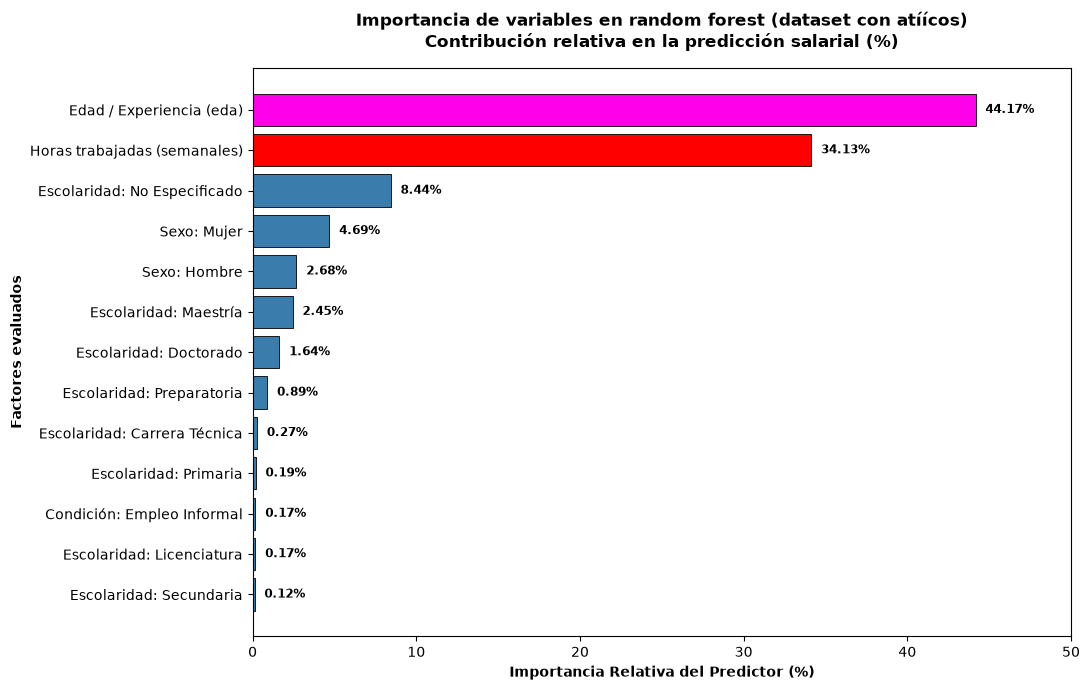

In [15]:
df_imp["Variable_Label"] = df_imp["Variable_Cod"].map(diccionario_rf)
df_imp["Porcentaje"] = df_imp["Importancia"] * 100
df_imp = df_imp.sort_values(by="Porcentaje", ascending=True)

os.makedirs("../outputs/figures", exist_ok=True)
plt.figure(figsize=(11, 7))

colores_rf = [
    "#3a7cab" if p < 10 else "#ff0000" if p < 40 else "#fe00e9"
    for p in df_imp["Porcentaje"]
]

bars = plt.barh(
    df_imp["Variable_Label"],
    df_imp["Porcentaje"],
    color=colores_rf,
    edgecolor="black",
    linewidth=0.6,
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.6,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        color="black",
    )

plt.title(
    "Importancia de variables en random forest (dataset con atíícos)\nContribución relativa en la predicción salarial (%)",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Importancia Relativa del Predictor (%)", fontweight="bold")

plt.ylabel("Factores evaluados", fontweight="bold")
plt.xlim(0, 50)
plt.tight_layout()

plt.savefig("../outputs/figures/rf_importancia_variables.png", dpi = 300)
plt.show()